# Parameter tuning of wCSET and GBF

One sweep, on one set of tuning spikes, for the parameters tuned in simulation:

- **wCSET:** harmonic decay β × depth-weighting exponent κ (grid of `harmonic-prior-tuning.ipynb`),
  with the project's empirical connectome, the one used to simulate the spikes.
- **GBF:** cutoff S, for our normalized prior and for the unnormalized prior of Wang et al. (2026).
- **sLORETA:** reference.
- **CSET:** not included yet (its solver is iterative and much slower); to be added to this sweep.

**Tuning spikes.** 50 spikes simulated by `simulate_tuning_spikes.py` with exactly the paper's
simulation (same simulator, connectome, head model, spike, propagation, noise and SNR settings),
one per region, in 50 regions spread over the cortex that are **not** in Study I's probe set.
They are stored in `/media/nino/DATA/SIMF/derivatives/simulations-tuning` (read-only here).

**Preprocessing and regularization** as in Study I's `solve_inverse.py`: crop [−0.02, 0.15] s,
SNR from the simulator's epoch baseline, `lambda2 = max(0.01, 1/SNR²)`.

**Metrics** as in Study I (`processing_simf.qmd`, `postprocess_score`): peak localization error at
the quarter-rising phase (qrp, 25% of the peak), and the spatial correlation across dipoles at every
time point of the crop. The full correlation curves are saved; the summaries use their mean over the
crop and their values at qrp and at the peak (pp).

`SWEEP_PILOT=1` runs one spike only (timing check). Results go to `results/simf/tuning/`, with the
tag `paper-metrics` (an earlier run with AP and hrp localization error is kept as `tuning_sweep.tsv`).

In [1]:
import os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

import mindmap as mm
from mindmap.analysis.functional.inverse.utils import compute_depth_prior
from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator
from mindmap.analysis.simulation import Source

mne.set_log_level("error")
PROJECT = Path("/home/nino/Manuscripts/wCSET")
sys.path.insert(0, str(PROJECT))
from scripts.data_manager import SimfManager

PILOT = os.environ.get("SWEEP_PILOT") == "1"
OUT = PROJECT / "results" / "simf" / "tuning"
OUT.mkdir(parents=True, exist_ok=True)
SUFFIX = "_paper-metrics" + ("_pilot" if PILOT else "")

SIM_TUNING = Path("/media/nino/DATA/SIMF/derivatives/simulations-tuning")
dm = SimfManager(str(PROJECT / "processing" / "simf.config.yml"))
dm.add_root("sim", SIM_TUNING)       # tuning spikes, not the paper's simulations
sub, task = "10", "spk"

crop = (-0.02, 0.15)
wcset_betas = [1, 2, 3, 5, 7, 10]
wcset_depths = [0, 0.2, 0.5, 0.8, 1.0]
gbf_cutoffs_norm = [50, 100, 150, 200, 300, 450, 600, 900, 1200, 1800, 2700, 4000]
gbf_cutoffs_raw = [300, 600, 900, 1200]
EPS = 1e-8
print(f"PILOT={PILOT}  spikes: {SIM_TUNING}  output: {OUT}")

PILOT=False  spikes: /media/nino/DATA/SIMF/derivatives/simulations-tuning  output: /home/nino/Manuscripts/wCSET/results/simf/tuning


## Subject-level data

In [2]:
fwd = dm.load(sub, "fwd", desc="inv")
simulator, _, _ = Simulator.load(SIM_TUNING / f"sub-{sub}" / "simulator")
baseline = tuple(simulator.epoch_config.baseline)
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000
n_lh = fwd["src"][0]["nuse"]

eig_con = dm.load(sub, "eig")                       # empirical connectome (Study I)
eig_lb = dm.load(sub, "eig", desc="beltrami")       # Laplace-Beltrami (GBF)
assert eig_lb["vec"].shape == (7465, 7464)
mode_is_lh = (eig_lb["vec"][:n_lh] ** 2).sum(0) > 0.5
hemi_counts = lambda S: (int(mode_is_lh[:S].sum()), int(S - mode_is_lh[:S].sum()))

index = pd.read_csv(SIM_TUNING / f"sub-{sub}" / "simulation_index.tsv", sep="\t")
index["region"] = index["source_index_list"].str.strip("[]'\"")
probe_set = set(pd.read_csv(PROJECT / "results/simf/intermediate/probe-set.csv")["region"])
assert not set(index["region"]) & probe_set
runs = index["run"].tolist()[:1] if PILOT else index["run"].tolist()
print(f"{len(index)} tuning spikes, baseline {baseline}, running {len(runs)}")

50 tuning spikes, baseline (-0.45, -0.2), running 50


## Methods

`RawLogGBF` is Wang et al.'s prior without our normalization, √(−ln μ_i) truncated at S
(defined here so mindmap is not modified).

In [3]:
class RawLogGBF(mm.analysis.inverse.wCSET):
    def compute_source_prior(self, gain_whitened):
        S = self.cutoff
        assert self.e[S - 1] < 1, "raw prior needs mu_S < 1"
        w = np.zeros_like(self.e, dtype=float)
        w[:S] = np.sqrt(-np.log(np.maximum(self.e[:S], EPS)))
        return compute_depth_prior(gain_whitened, self.depth_coeff)[:, None] * (self.U * w)

def configs():
    for beta in wcset_betas:
        for depth in wcset_depths:
            yield dict(method="wcset", beta=beta, depth=depth), lambda fwd, ncov, beta=beta, depth=depth: mm.analysis.inverse.wCSET(
                forward=fwd, noise_cov=ncov, depth=depth, eigenvectors=eig_con["vec"], eigenvalues=eig_con["val"],
                harm=beta, harmonic_method="lowpass")
    for S in gbf_cutoffs_norm:
        yield dict(method="gbf", prior="normalized", S=S), lambda fwd, ncov, S=S: mm.analysis.inverse.wCSET(
            forward=fwd, noise_cov=ncov, depth=0, eigenvectors=eig_lb["vec"], eigenvalues=eig_lb["val"],
            harmonic_method="logpass", cutoff=S)
    for S in gbf_cutoffs_raw:
        yield dict(method="gbf", prior="raw", S=S), lambda fwd, ncov, S=S: RawLogGBF(
            forward=fwd, noise_cov=ncov, depth=0, eigenvectors=eig_lb["vec"], eigenvalues=eig_lb["val"],
            harmonic_method="logpass", cutoff=S)

n_configs = sum(1 for _ in configs()) + 1
print(n_configs, "solves per spike (incl. sLORETA)")

47 solves per spike (incl. sLORETA)


## Sweep

Rows are appended to the TSV after each spike, so a partial run keeps its results.

In [4]:
def evaluate(ground, sol, qrp, pp, mask):
    corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson")).ravel()
    return corr, dict(
        loc_err_qrp=find_peak_localization_error(sol.data[:, qrp], mask, dipole_positions)["distance_mm"],
        corr_qrp=float(corr[qrp]), corr_pp=float(corr[pp]), corr_mean=float(np.nanmean(corr)))

def cfg_label(cfg):
    if cfg["method"] == "wcset":
        return f"wcset {cfg['beta']:g}/{cfg['depth']:g}"
    if cfg["method"] == "gbf":
        return f"gbf {cfg['prior']} {cfg['S']}"
    return cfg["method"]

fout = OUT / f"tuning_sweep{SUFFIX}.tsv"
fcurves = OUT / f"tuning_corr-curves{SUFFIX}.tsv"
for f in (fout, fcurves):
    if f.exists():
        f.unlink()
t_all = time.time()
for k, run in enumerate(runs):
    t0 = time.time()
    row = index[index["run"] == run].iloc[0]
    ave = dm.load(sub, "ave", run=run, task=task)
    ncov = dm.load(sub, "cov", run=run, task=task)
    gold = dm.load(sub, "gold", run=run, task=task)
    data, ground = ave.copy().crop(*crop), gold.copy().crop(*crop)
    snr, _ = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=baseline, noise_cov=ncov)
    lambda2 = max(0.01, 1.0 / (snr.max() ** 2))
    qrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.25, as_idx=True)[0]
    pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]
    src = Source.load(SIM_TUNING / f"sub-{sub}" / "sources" / row["source_file"])
    mask = np.asarray(src.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras), bool)

    rows, curves = [], {}
    def score(cfg, sol):
        corr, m = evaluate(ground, sol, qrp, pp, mask)
        rows.append(dict(run=run, region=row["region"], lambda2=lambda2, qrp_time=data.times[qrp], pp_time=data.times[pp], **cfg, **m))
        curves[cfg_label(cfg)] = corr
    for cfg, make in configs():
        score(cfg, make(fwd, ncov).solve(data, lambda2))
    inv = mne.minimum_norm.make_inverse_operator(data.info, fwd, ncov, fixed=True, depth=None)
    score(dict(method="sloreta"), mne.minimum_norm.apply_inverse(data, inv, lambda2, method="sLORETA"))

    df = pd.DataFrame(rows).reindex(columns=["run", "region", "lambda2", "qrp_time", "pp_time", "method", "beta", "depth",
                                             "prior", "S", "loc_err_qrp", "corr_qrp", "corr_pp", "corr_mean"])
    df.to_csv(fout, sep="\t", index=False, mode="a", header=(k == 0))
    cdf = pd.DataFrame(curves, index=pd.Index(np.round(data.times, 4), name="time")).reset_index().melt(
        id_vars="time", var_name="cfg", value_name="r").assign(run=run)
    cdf.to_csv(fcurves, sep="\t", index=False, mode="a", header=(k == 0))
    print(f"[{k+1}/{len(runs)}] run {run} ({row['region']}): {len(rows)} solves in {time.time()-t0:.1f}s "
          f"(elapsed {(time.time()-t_all)/60:.1f} min)", flush=True)

scores = pd.read_csv(fout, sep="\t")
assert not scores[["loc_err_qrp", "corr_qrp", "corr_pp", "corr_mean"]].isna().any().any()
curves = pd.read_csv(fcurves, sep="\t")
print(len(scores), "rows;", curves.time.nunique(), "time points per curve")

[1/50] run 1 (ctx-rh-superiorfrontal_2): 47 solves in 180.4s (elapsed 3.0 min)


[2/50] run 2 (ctx-lh-lateraloccipital_2): 47 solves in 164.9s (elapsed 5.8 min)


[3/50] run 3 (ctx-lh-middletemporal_7): 47 solves in 183.3s (elapsed 8.8 min)


[4/50] run 4 (ctx-rh-postcentral_12): 47 solves in 191.7s (elapsed 12.0 min)


[5/50] run 5 (ctx-rh-inferiortemporal_5): 47 solves in 174.1s (elapsed 14.9 min)


[6/50] run 6 (ctx-lh-caudalmiddlefrontal_2): 47 solves in 181.2s (elapsed 17.9 min)


... (41 outputs left out)

[48/50] run 48 (ctx-rh-insula_6): 47 solves in 173.8s (elapsed 138.8 min)


[49/50] run 49 (ctx-rh-lateraloccipital_10): 47 solves in 185.0s (elapsed 141.9 min)


[50/50] run 50 (ctx-rh-inferiortemporal_2): 47 solves in 190.7s (elapsed 145.1 min)


2350 rows; 44 time points per curve


## wCSET: β × κ

loc_err_median  loc_err_mean  corr_mean  corr_qrp  corr_pp
beta depth                                                            
1.0  0.0            29.755        39.745      0.152     0.283    0.409
     0.2            27.843        39.236      0.150     0.286    0.399
     0.5            22.870        34.302      0.141     0.276    0.363
     0.8            21.694        34.901      0.124     0.249    0.313
     1.0            29.390        37.950      0.111     0.226    0.279
2.0  0.0            12.653        26.330      0.220     0.415    0.554
     0.2             8.139        23.772      0.212     0.409    0.530
     0.5             9.720        20.300      0.189     0.378    0.464
     0.8            17.688        26.127      0.159     0.327    0.387
     1.0            19.153        29.379      0.138     0.289    0.338
3.0  0.0             6.692        19.571      0.240     0.455    0.594
     0.2             6.210        16.505      0.229     0.442    0.563
     0.5             6.674        19.192      0.200     0.398    0.487
     0.8            12.440        25.147      0.166     0.344    0.406
     1.0            23.450        30.554      0.146     0.304    0.356
5.0  0.0             4.168        15.794      0.247     0.458    0.605
     0.2             6.387        19.360      0.230     0.435    0.568
     0.5             7.796        19.387      0.198     0.386    0.491
     0.8            14.171        26.423      0.168     0.339    0.417
     1.0            24.314        30.701      0.150     0.306    0.372
7.0  0.0             4.550        20.623      0.250     0.448    0.614
     0.2             9.055        21.962      0.232     0.426    0.578
     0.5            10.060        19.905      0.200     0.376    0.500
     0.8            15.031        28.009      0.171     0.335    0.427
     1.0            23.243        30.198      0.155     0.309    0.384
10.0 0.0             8.721        20.631      0.255     0.436    0.626
     0.2            13.086        22.909      0.237     0.416    0.593
     0.5            11.254        19.566      0.206     0.367    0.516
     0.8            18.274        26.512      0.176     0.331    0.434
     1.0            17.869        25.604      0.161     0.309    0.393

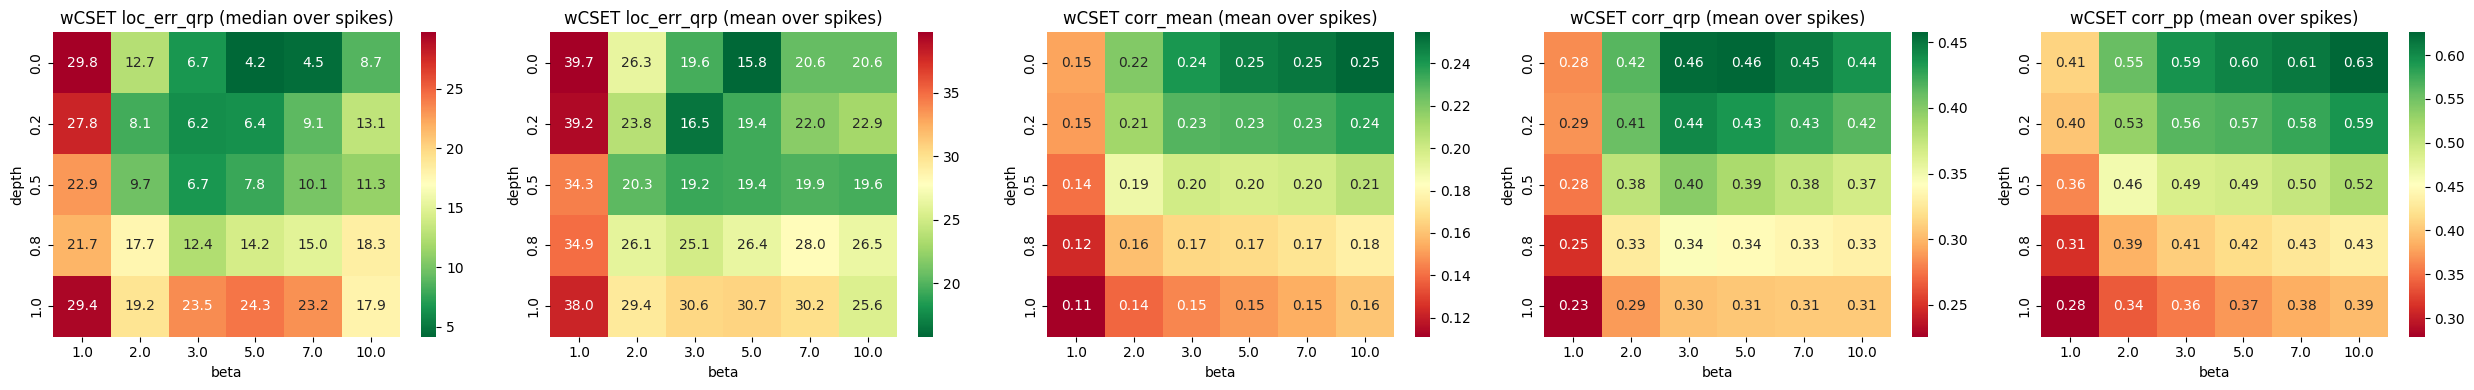

In [5]:
import seaborn as sns
w = scores[scores.method == "wcset"].copy()
w["cfg"] = [f"{b:g}/{d:g}" for b, d in zip(w.beta, w.depth)]
metrics = [("loc_err_qrp", "median", "RdYlGn_r"), ("loc_err_qrp", "mean", "RdYlGn_r"),
           ("corr_mean", "mean", "RdYlGn"), ("corr_qrp", "mean", "RdYlGn"), ("corr_pp", "mean", "RdYlGn")]
fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, (m, agg, cmap) in zip(axes, metrics):
    grid = w.pivot_table(index="depth", columns="beta", values=m, aggfunc=agg)
    sns.heatmap(grid, annot=True, fmt=".2f" if "corr" in m else ".1f", cmap=cmap, ax=ax); ax.set_title(f"wCSET {m} ({agg} over spikes)")
fig.tight_layout(); fig.savefig(OUT / f"tuning_wcset{SUFFIX}.png", dpi=150)

wsum = w.groupby(["beta", "depth"]).agg(loc_err_median=("loc_err_qrp", "median"), loc_err_mean=("loc_err_qrp", "mean"),
                                        corr_mean=("corr_mean", "mean"), corr_qrp=("corr_qrp", "mean"), corr_pp=("corr_pp", "mean"))
wsum.to_csv(OUT / f"tuning_wcset_summary{SUFFIX}.tsv", sep="\t")
wsum.round(3)

Paired against the paper's setting (β = 5, κ = 0.2): median and mean paired difference, and share of spikes where each setting is better / worse.

In [6]:
def paired(df, ref, metric, lower_is_better):
    p = df.pivot_table(index="run", columns="cfg", values=metric); r = p[ref]
    better, worse = (p.lt, p.gt) if lower_is_better else (p.gt, p.lt)
    return pd.DataFrame({"median diff": p.sub(r, axis=0).median(), "mean diff": p.sub(r, axis=0).mean(),
                         "better %": better(r, axis=0).mean() * 100, "worse %": worse(r, axis=0).mean() * 100})

wp = pd.concat({"loc_err_qrp": paired(w, "5/0.2", "loc_err_qrp", True),
                "corr_mean": paired(w, "5/0.2", "corr_mean", False)}, axis=1)
wp.to_csv(OUT / f"tuning_wcset_paired{SUFFIX}.tsv", sep="\t")
wp.round(3)

loc_err_qrp                              corr_mean                     \
       median diff mean diff better % worse % median diff mean diff better %   
cfg                                                                            
1/0         10.280    20.384     26.0    68.0      -0.079    -0.078      0.0   
1/0.2        6.389    19.876     30.0    62.0      -0.079    -0.080      0.0   
1/0.5        5.062    14.941     32.0    60.0      -0.090    -0.090      0.0   
1/0.8       13.530    15.541     26.0    72.0      -0.106    -0.106      0.0   
1/1         15.781    18.590     22.0    78.0      -0.120    -0.119      0.0   
10/0         0.000     1.271     28.0    36.0       0.023     0.024     98.0   
10/0.2       0.000     3.549     24.0    34.0       0.007     0.007     72.0   
10/0.5       0.000     0.206     32.0    42.0      -0.023    -0.024      8.0   
10/0.8       2.493     7.151     26.0    56.0      -0.049    -0.054      2.0   
10/1         2.493     6.244     30.0    56.0      -0.064    -0.069      0.0   
2/0          1.069     6.969     30.0    56.0      -0.013    -0.011     18.0   
2/0.2        0.117     4.412     32.0    50.0      -0.021    -0.018     12.0   
2/0.5        0.000     0.939     42.0    42.0      -0.040    -0.041      4.0   
2/0.8        6.047     6.767     28.0    66.0      -0.070    -0.071      0.0   
2/1          6.878    10.019     26.0    68.0      -0.093    -0.092      0.0   
3/0          0.000     0.211     36.0    44.0       0.008     0.010     82.0   
3/0.2        0.000    -2.855     24.0    30.0      -0.003    -0.001     30.0   
3/0.5        0.000    -0.169     32.0    30.0      -0.030    -0.031      2.0   
3/0.8        0.099     5.786     30.0    50.0      -0.064    -0.064      0.0   
3/1          6.287    11.193     30.0    62.0      -0.083    -0.085      0.0   
5/0          0.000    -3.566     26.0    22.0       0.015     0.017     96.0   
5/0.2        0.000     0.000      0.0     0.0       0.000     0.000      0.0   
5/0.5        0.000     0.027     28.0    30.0      -0.029    -0.032      0.0   
5/0.8        0.000     7.063     30.0    48.0      -0.058    -0.063      0.0   
5/1          2.093    11.340     32.0    56.0      -0.074    -0.080      0.0   
7/0          0.000     1.263     18.0    28.0       0.019     0.020     98.0   
7/0.2        0.000     2.602     12.0    26.0       0.003     0.002     64.0   
7/0.5        0.000     0.544     28.0    38.0      -0.028    -0.031      0.0   
7/0.8        0.303     8.648     30.0    50.0      -0.054    -0.060      0.0   
7/1          2.231    10.838     30.0    56.0      -0.068    -0.075      0.0   

                
       worse %  
cfg             
1/0      100.0  
1/0.2    100.0  
1/0.5    100.0  
1/0.8    100.0  
1/1      100.0  
10/0       2.0  
10/0.2    28.0  
10/0.5    92.0  
10/0.8    98.0  
10/1     100.0  
2/0       82.0  
2/0.2     88.0  
2/0.5     96.0  
2/0.8    100.0  
2/1      100.0  
3/0       18.0  
3/0.2     70.0  
3/0.5     98.0  
3/0.8    100.0  
3/1      100.0  
5/0        4.0  
5/0.2      0.0  
5/0.5    100.0  
5/0.8    100.0  
5/1      100.0  
7/0        2.0  
7/0.2     36.0  
7/0.5    100.0  
7/0.8    100.0  
7/1      100.0

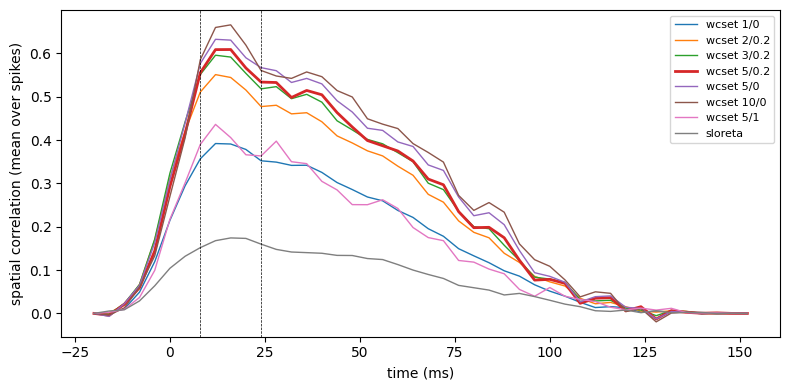

In [7]:
# correlation over time, mean over spikes, for a few settings
t_qrp, t_pp = scores.qrp_time.median(), scores.pp_time.median()
show = ["wcset 1/0", "wcset 2/0.2", "wcset 3/0.2", "wcset 5/0.2", "wcset 5/0", "wcset 10/0", "wcset 5/1", "sloreta"]
fig, ax = plt.subplots(figsize=(8, 4))
for c in show:
    m = curves[curves.cfg == c].groupby("time").r.mean()
    ax.plot(m.index * 1000, m.values, label=c, lw=2 if c == "wcset 5/0.2" else 1)
for t in (t_qrp, t_pp):
    ax.axvline(t * 1000, color="k", lw=0.5, ls="--")
ax.set_xlabel("time (ms)"); ax.set_ylabel("spatial correlation (mean over spikes)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / f"tuning_wcset_corr-time{SUFFIX}.png", dpi=150)

## GBF: cutoff S

,prior,S,loc_err_median,loc_err_mean,corr_mean,corr_qrp,corr_pp,S_lh,S_rh
0,normalized,50.0,19.404,28.574,0.197,0.261,0.504,25,25
1,normalized,100.0,24.505,30.145,0.189,0.331,0.506,51,49
2,normalized,150.0,14.011,24.912,0.196,0.374,0.501,76,74
3,normalized,200.0,9.897,19.317,0.197,0.378,0.499,101,99
4,normalized,300.0,10.950,21.977,0.192,0.365,0.491,151,149
5,normalized,450.0,12.887,24.439,0.183,0.345,0.476,229,221
6,normalized,600.0,11.485,22.825,0.177,0.330,0.461,304,296
7,normalized,900.0,11.063,27.944,0.167,0.311,0.441,457,443
8,normalized,1200.0,20.265,31.686,0.161,0.298,0.428,608,592
9,normalized,1800.0,24.510,34.430,0.154,0.282,0.410,915,885


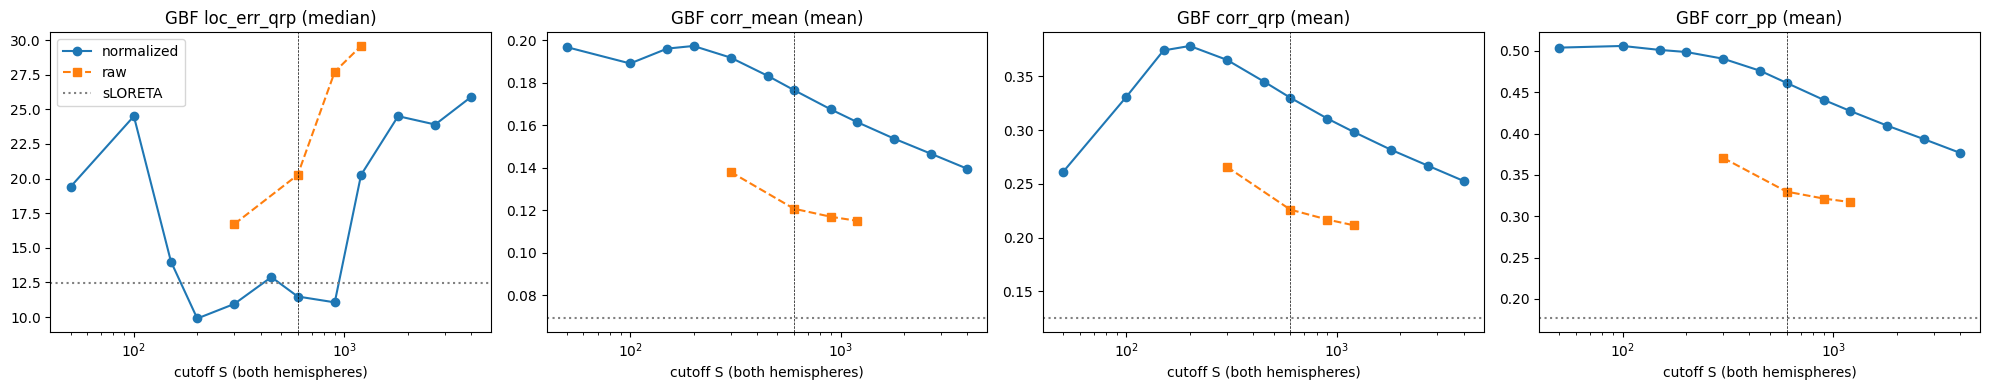

In [8]:
g = scores[scores.method == "gbf"].copy()
g["cfg"] = g.prior + " " + g.S.astype(int).astype(str)
gsum = g.groupby(["prior", "S"]).agg(loc_err_median=("loc_err_qrp", "median"), loc_err_mean=("loc_err_qrp", "mean"),
                                     corr_mean=("corr_mean", "mean"), corr_qrp=("corr_qrp", "mean"), corr_pp=("corr_pp", "mean")).reset_index()
gsum[["S_lh", "S_rh"]] = [hemi_counts(int(S)) for S in gsum.S]
gsum.to_csv(OUT / f"tuning_gbf_summary{SUFFIX}.tsv", sep="\t", index=False)

sl = scores[scores.method == "sloreta"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (m, col, agg) in zip(axes, [("loc_err_qrp", "loc_err_median", "median"), ("corr_mean", "corr_mean", "mean"),
                                    ("corr_qrp", "corr_qrp", "mean"), ("corr_pp", "corr_pp", "mean")]):
    for prior, style in (("normalized", "o-"), ("raw", "s--")):
        s = gsum[gsum.prior == prior]
        ax.plot(s.S, s[col], style, label=prior)
    ax.axhline(getattr(sl[m], agg)(), color="grey", ls=":", label="sLORETA")
    ax.axvline(600, color="k", lw=0.5, ls="--")
    ax.set_xscale("log"); ax.set_xlabel("cutoff S (both hemispheres)"); ax.set_title(f"GBF {m} ({agg})")
axes[0].legend(); fig.tight_layout(); fig.savefig(OUT / f"tuning_gbf{SUFFIX}.png", dpi=150)
gsum.round(3)

In [9]:
gp = pd.concat({"loc_err_qrp": paired(g, "normalized 150", "loc_err_qrp", True),
                "corr_mean": paired(g, "normalized 150", "corr_mean", False)}, axis=1)
gp.to_csv(OUT / f"tuning_gbf_paired{SUFFIX}.tsv", sep="\t")
gp.round(3)

loc_err_qrp                              corr_mean            \
                median diff mean diff better % worse % median diff mean diff   
cfg                                                                            
normalized 100        0.593     5.233     38.0    50.0      -0.008    -0.007   
normalized 1200       4.616     6.773     36.0    52.0      -0.035    -0.035   
normalized 150        0.000     0.000      0.0     0.0       0.000     0.000   
normalized 1800       5.702     9.518     36.0    58.0      -0.042    -0.042   
normalized 200        0.000    -5.596     30.0    28.0       0.001     0.001   
normalized 2700       5.806     9.886     36.0    58.0      -0.049    -0.050   
normalized 300        0.000    -2.936     40.0    36.0      -0.005    -0.004   
normalized 4000       6.657    14.163     32.0    60.0      -0.056    -0.057   
normalized 450        0.000    -0.474     40.0    44.0      -0.012    -0.013   
normalized 50         2.411     3.661     42.0    50.0       0.002     0.001   
normalized 600        0.000    -2.087     44.0    40.0      -0.019    -0.020   
normalized 900        0.000     3.032     40.0    48.0      -0.030    -0.029   
raw 1200              7.179    16.494     34.0    62.0      -0.080    -0.081   
raw 300               2.737     2.497     32.0    52.0      -0.060    -0.058   
raw 600               2.407     7.993     42.0    52.0      -0.074    -0.075   
raw 900               6.610    13.992     34.0    62.0      -0.079    -0.079   

                                  
                better % worse %  
cfg                               
normalized 100      40.0    60.0  
normalized 1200      4.0    96.0  
normalized 150       0.0     0.0  
normalized 1800      2.0    98.0  
normalized 200      56.0    44.0  
normalized 2700      2.0    98.0  
normalized 300      34.0    66.0  
normalized 4000      2.0    98.0  
normalized 450      18.0    82.0  
normalized 50       52.0    48.0  
normalized 600      14.0    86.0  
normalized 900       4.0    96.0  
raw 1200             0.0   100.0  
raw 300              0.0   100.0  
raw 600              0.0   100.0  
raw 900              0.0   100.0

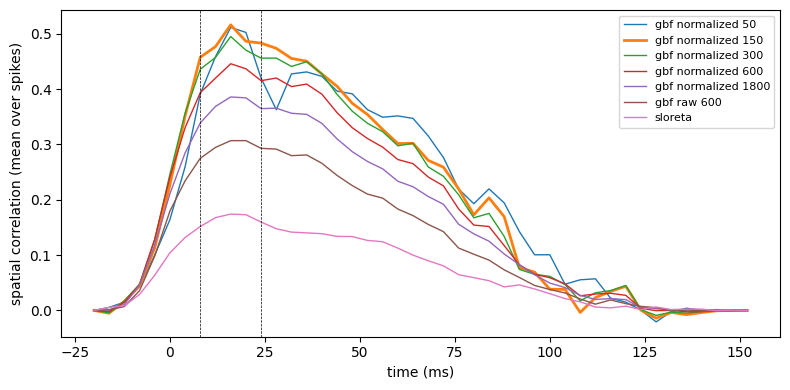

In [10]:
show = ["gbf normalized 50", "gbf normalized 150", "gbf normalized 300", "gbf normalized 600", "gbf normalized 1800", "gbf raw 600", "sloreta"]
fig, ax = plt.subplots(figsize=(8, 4))
for c in show:
    m = curves[curves.cfg == c].groupby("time").r.mean()
    ax.plot(m.index * 1000, m.values, label=c, lw=2 if c == "gbf normalized 150" else 1)
for t in (t_qrp, t_pp):
    ax.axvline(t * 1000, color="k", lw=0.5, ls="--")
ax.set_xlabel("time (ms)"); ax.set_ylabel("spatial correlation (mean over spikes)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / f"tuning_gbf_corr-time{SUFFIX}.png", dpi=150)

In [11]:
print("sLORETA:", sl[["loc_err_qrp", "corr_mean", "corr_qrp", "corr_pp"]].agg(["median", "mean"]).round(3).to_dict())

sLORETA: {'loc_err_qrp': {'median': 12.426, 'mean': 28.695}, 'corr_mean': {'median': 0.068, 'mean': 0.069}, 'corr_qrp': {'median': 0.124, 'mean': 0.125}, 'corr_pp': {'median': 0.173, 'mean': 0.176}}
